# Chapter 9: Dates and time series in pandas

Almost every real dataset has a clock in it: when an order was placed, when a sensor fired, when a customer joined. Questions like "is December busier than September?" or "does rain hurt sales?" are questions about time, and pandas has a whole toolkit for them.

By the end of this chapter you will be able to turn text into real dates, pull out the hour or weekday of each order, slice a table by date, roll daily numbers up into weeks and months, smooth a noisy series with a rolling average, fill in missing days, and join sales with the weather. It builds on Chapter 6 (loading and filtering) and Chapter 8 (grouping and merging).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("pandas version:", pd.__version__)

pandas version: 3.1.1


## 9.1 Turning text into dates

A CSV file has no idea what a date is: it only stores text. If you load `orders.csv` without telling pandas otherwise, the `timestamp` column is just strings, and strings sort and compare like words, not like moments in time.

In [2]:
raw = pd.read_csv("data/orders.csv")
print(raw["timestamp"].dtype)
print(raw["timestamp"].iloc[0], type(raw["timestamp"].iloc[0]))

str
2024-01-01 17:24:00 <class 'str'>


There are two ways to fix this. Convert an existing column with `pd.to_datetime`, or ask `read_csv` to parse the column while loading with `parse_dates=` (see Chapter 6).

In [3]:
raw["timestamp"] = pd.to_datetime(raw["timestamp"])
print(raw["timestamp"].dtype)

orders = pd.read_csv("data/orders.csv", parse_dates=["timestamp"])
orders["revenue"] = orders["qty"] * orders["unit_price"]
print(orders[["timestamp", "item", "revenue"]].head(3))

datetime64[us]
            timestamp         item  revenue
0 2024-01-01 17:24:00    Croissant      140
1 2024-01-01 12:28:00  Masala Chai      180
2 2024-01-01 16:56:00     Sandwich      220


The dtype is now `datetime64[us]`: a date and time stored with microsecond precision. (Older pandas versions showed `datetime64[ns]`; both behave the same for everything in this chapter.)

Our file uses the ISO format `2024-01-01 17:24:00`, which pandas reads without any help. Other formats are ambiguous: is `03/04/2024` the 3rd of April or the 4th of March? Pass `format=` to say exactly what you mean, and `errors="coerce"` to turn unreadable values into `NaT` ("not a time", the date version of `NaN`) instead of crashing.

In [4]:
text = pd.Series(["03/04/2024 09:15", "25/12/2024 18:40", "not a date"])
parsed = pd.to_datetime(text, format="%d/%m/%Y %H:%M", errors="coerce")
print(parsed)

0   2024-04-03 09:15:00
1   2024-12-25 18:40:00
2                   NaT
dtype: datetime64[us]


The first value became the 3rd of April because we said the day comes first (`%d/%m`). The bad value became `NaT`, which you can find later with `isna()` (Chapter 7 covers cleaning such values).

## 9.2 Timestamp and Timedelta

A single moment in pandas is a `Timestamp`. The gap between two moments is a `Timedelta`. Subtracting timestamps gives a timedelta, and adding a timedelta to a timestamp moves it.

In [5]:
first = orders["timestamp"].min()
last = orders["timestamp"].max()
span = last - first

print(type(first).__name__, first)
print(type(span).__name__, span)
print("days covered:", span.days)

Timestamp 2024-01-01 07:01:00
Timedelta 365 days 14:37:00
days covered: 365


You can build timedeltas from text or with `pd.Timedelta(hours=...)`, and use them for date maths such as "30 days after joining".

In [6]:
opening = pd.Timestamp("2024-06-01 08:00")
print(opening + pd.Timedelta(hours=13, minutes=30))     # closing time
print(opening + pd.Timedelta("30D"))                    # a month-ish later
print(pd.Timestamp("2024-12-25").day_name())            # what weekday was Christmas?

2024-06-01 21:30:00
2024-07-01 08:00:00
Wednesday


The same arithmetic works on whole columns. Here is the age of every customer account at the end of 2024:

In [7]:
customers = pd.read_csv("data/customers.csv", parse_dates=["joined"])
tenure = pd.Timestamp("2024-12-31") - customers["joined"]
print(tenure.head(3))
print("median tenure in days:", tenure.dt.days.median())

0   853 days
1   287 days
2   239 days
Name: joined, dtype: timedelta64[us]
median tenure in days: 594.0


### A word on time zones

Our timestamps are **naive**: they carry no time zone, and we simply understand them as Indian time. If you ever combine data from different countries, attach a zone with `tz_localize` and convert with `tz_convert`.

In [8]:
t = pd.Timestamp("2024-03-15 09:30").tz_localize("Asia/Kolkata")
print(t)
print(t.tz_convert("UTC"))

2024-03-15 09:30:00+05:30
2024-03-15 04:00:00+00:00


India is UTC+05:30, so 09:30 in Pune is 04:00 UTC. For a single-country dataset like ours, staying naive is fine.

## 9.3 The .dt accessor

Just as `.str` gives string methods to a text column, `.dt` gives date methods to a datetime column. It lets you pull out parts of each timestamp as new columns, which you can then group by (see Chapter 8).

In [9]:
ts = orders["timestamp"]
parts = pd.DataFrame({
    "timestamp": ts,
    "hour": ts.dt.hour,
    "month": ts.dt.month,
    "day_of_week": ts.dt.day_of_week,   # Monday=0 ... Sunday=6
    "day_name": ts.dt.day_name(),
})
print(parts.head())

            timestamp  hour  month  day_of_week day_name
0 2024-01-01 17:24:00    17      1            0   Monday
1 2024-01-01 12:28:00    12      1            0   Monday
2 2024-01-01 16:56:00    16      1            0   Monday
3 2024-01-01 13:55:00    13      1            0   Monday
4 2024-01-01 13:55:00    13      1            0   Monday


Note that `hour`, `month` and `day_of_week` are attributes (no brackets), while `day_name()` is a method. Now we can answer "when is the shop busy?" with a single `value_counts`:

In [10]:
orders_per_hour = ts.dt.hour.value_counts().sort_index()
print(orders_per_hour)

timestamp
7     1930
8     5463
9     6714
10    4622
11    3255
12    4132
13    4799
14    3230
15    2695
16    3396
17    3961
18    3274
19    2550
20    1857
21    1325
Name: count, dtype: int64


There are two clear peaks: a morning rush around 9 o'clock and a smaller lunch bump at 13:00. The same trick by weekday shows the weekend effect:

In [11]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = orders.groupby(ts.dt.day_name())["revenue"].sum().reindex(day_order)
print((by_day / 1000).round(0))   # thousands of rupees over the whole year

timestamp
Monday       1278.0
Tuesday      1230.0
Wednesday    1169.0
Thursday     1240.0
Friday       1390.0
Saturday     1688.0
Sunday       1605.0
Name: revenue, dtype: float64


Saturday and Sunday bring in clearly more than any weekday. We used `reindex` to put the days in calendar order instead of alphabetical order.

Two more helpers you will use a lot: `dt.normalize()` keeps the date but sets the time to midnight (handy for "which day was this?"), and `dt.to_period("M")` labels each timestamp with its month.

In [12]:
print(ts.dt.normalize().head(3))
print(ts.dt.to_period("M").head(3))

0   2024-01-01
1   2024-01-01
2   2024-01-01
Name: timestamp, dtype: datetime64[us]
0    2024-01
1    2024-01
2    2024-01
Name: timestamp, dtype: period[M]


## 9.4 DatetimeIndex and slicing by date strings

When the timestamps become the **index** of a DataFrame, you get a `DatetimeIndex`, and pandas unlocks a very readable way of selecting rows: by date strings, including partial ones.

In [13]:
ts_orders = orders.set_index("timestamp").sort_index()
print(type(ts_orders.index).__name__)
print(ts_orders.loc["2024-03"].shape)              # every order in March
print(ts_orders.loc["2024-12-25"].shape)           # every order on Christmas Day

DatetimeIndex
(4764, 9)
(147, 9)


A partial string like `"2024-03"` means "the whole of March". Slices with `:` include **both** ends, which is what you want with dates.

In [14]:
first_week = ts_orders.loc["2024-01-01":"2024-01-07"]
print(first_week.index.min(), "to", first_week.index.max())
print("revenue in the first week:", first_week["revenue"].sum())

2024-01-01 07:01:00 to 2024-01-07 21:52:00
revenue in the first week: 190570


Sort the index first (we did with `sort_index()`). Slicing an unsorted DatetimeIndex can be slow or raise an error.

## 9.5 Resampling: from orders to days, weeks and months

`resample` is `groupby` for time. You give it a frequency, and it puts every row into a time bucket of that size, then you aggregate. The most common codes are `"D"` (day), `"W"` (week ending Sunday), `"ME"` (month end), `"QE"` (quarter end) and `"h"` (hour).

In [15]:
daily = ts_orders["revenue"].resample("D").sum()
print(daily.head())
print("days:", len(daily))

timestamp
2024-01-01    27270
2024-01-02    23570
2024-01-03    22240
2024-01-04    21070
2024-01-05    27350
Freq: D, Name: revenue, dtype: int64
days: 366


53,000 order lines became 366 daily totals (2024 is a leap year). Let's look at them. This is a quick line plot; Chapter 10 explains every line of plotting code.

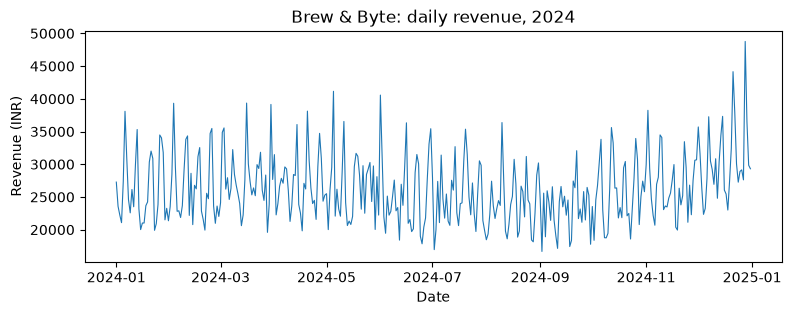

In [16]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(daily.index, daily.values, linewidth=0.8)
ax.set_title("Brew & Byte: daily revenue, 2024")
ax.set_xlabel("Date")
ax.set_ylabel("Revenue (INR)")
plt.show()

The line is jagged because weekends are busier than weekdays, but you can already see a dip in the monsoon months and a jump in December. Weekly and monthly totals make the trend clearer.

In [17]:
weekly = ts_orders["revenue"].resample("W").sum()
monthly = ts_orders["revenue"].resample("ME").sum()
print(weekly.tail(3))
print(monthly)

timestamp
2024-12-22    216380
2024-12-29    228280
2025-01-05     59160
Freq: W-SUN, Name: revenue, dtype: int64
timestamp
2024-01-31    810050
2024-02-29    772620
2024-03-31    860950
2024-04-30    811350
2024-05-31    818630
2024-06-30    765560
2024-07-31    777190
2024-08-31    744410
2024-09-30    692250
2024-10-31    789920
2024-11-30    804340
2024-12-31    952570
Freq: ME, Name: revenue, dtype: int64


Each bucket is labelled by its **end** date. Look at the last weekly value: the week ending 5 January 2025 only contains 30 and 31 December, so it is much smaller. Watch out for partial buckets at the edges before you compare them.

The monthly view confirms the story: September is the weakest month and December the strongest.

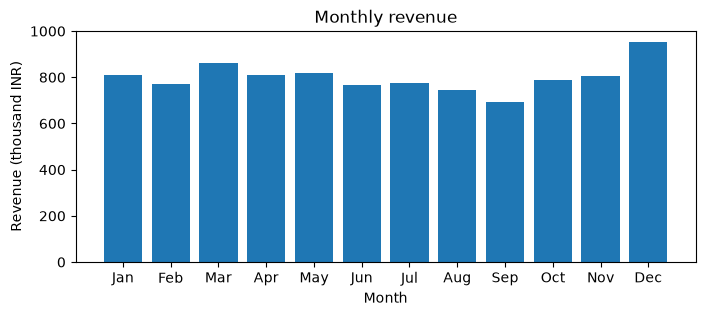

In [18]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(monthly.index.strftime("%b"), monthly.values / 1000)
ax.set_title("Monthly revenue")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (thousand INR)")
plt.show()

`resample` takes any aggregation, and several at once with `agg`, just like `groupby` (see Chapter 8):

In [19]:
weekly_stats = ts_orders.resample("W").agg(
    lines=("order_id", "count"),
    revenue=("revenue", "sum"),
    cups=("qty", "sum"),
)
print(weekly_stats.head(3))

            lines  revenue  cups
timestamp                       
2024-01-07   1066   190570  1336
2024-01-14   1032   185210  1298
2024-01-21    992   172300  1224


## 9.6 Rolling averages and changes over time

Daily numbers are noisy. A **rolling average** replaces each day with the mean of a window of days around it, which smooths out the weekend wiggle. `rolling(7)` uses the current day and the six before it.

In [20]:
roll7 = daily.rolling(7).mean()
print(roll7.head(8))

timestamp
2024-01-01             NaN
2024-01-02             NaN
2024-01-03             NaN
2024-01-04             NaN
2024-01-05             NaN
2024-01-06             NaN
2024-01-07    27224.285714
2024-01-08    26844.285714
Freq: D, Name: revenue, dtype: float64


The first six values are `NaN` because a full 7-day window is not available yet. Pass `min_periods=1` if you prefer a partial average at the start.

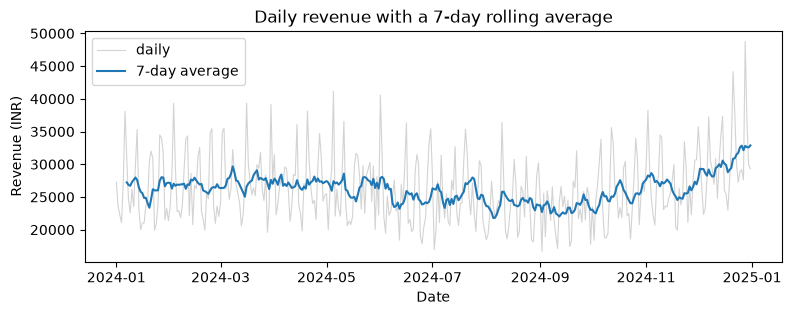

In [21]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(daily.index, daily.values, color="lightgray", linewidth=0.8, label="daily")
ax.plot(roll7.index, roll7.values, color="tab:blue", label="7-day average")
ax.set_title("Daily revenue with a 7-day rolling average")
ax.set_xlabel("Date")
ax.set_ylabel("Revenue (INR)")
ax.legend()
plt.show()

The blue line removes the weekly pattern and shows the slower trend: a sag from June to September and a climb in December.

To compare each value with an earlier one, use `shift`, `diff` and `pct_change`:

| Method | Gives you |
|---|---|
| `s.shift(1)` | the previous value, moved down one row |
| `s.diff()` | this value minus the previous one |
| `s.pct_change()` | the relative change: `(this - previous) / previous` |

In [22]:
growth = pd.DataFrame({
    "revenue": monthly,
    "previous": monthly.shift(1),
    "change": monthly.diff(),
    "pct": (monthly.pct_change() * 100).round(1),
})
growth.index = growth.index.strftime("%b")
print(growth)

           revenue  previous    change   pct
timestamp                                   
Jan         810050       NaN       NaN   NaN
Feb         772620  810050.0  -37430.0  -4.6
Mar         860950  772620.0   88330.0  11.4
Apr         811350  860950.0  -49600.0  -5.8
May         818630  811350.0    7280.0   0.9
Jun         765560  818630.0  -53070.0  -6.5
Jul         777190  765560.0   11630.0   1.5
Aug         744410  777190.0  -32780.0  -4.2
Sep         692250  744410.0  -52160.0  -7.0
Oct         789920  692250.0   97670.0  14.1
Nov         804340  789920.0   14420.0   1.8
Dec         952570  804340.0  148230.0  18.4


December grew about 18% on November, the biggest jump of the year. `shift` also takes larger steps: `daily.shift(7)` is "the same weekday last week", a fairer comparison for a business with a weekly rhythm.

In [23]:
week_on_week = (daily / daily.shift(7) - 1) * 100
print(week_on_week.loc["2024-12-20":"2024-12-26"].round(1))

timestamp
2024-12-20     6.7
2024-12-21    28.3
2024-12-22     1.6
2024-12-23    15.4
2024-12-24     7.1
2024-12-25    25.7
2024-12-26     6.4
Freq: D, Name: revenue, dtype: float64


## 9.7 Date ranges and filling in missing days

`groupby` only creates rows for dates that actually appear in the data. If nothing was sold on a day, that day is simply missing, and a missing day is not the same as a zero. Averages and rolling windows will be wrong if you forget this.

Green Tea at the small S2 store does not sell every day:

In [24]:
s2_tea = orders[(orders["store_id"] == "S2") & (orders["item"] == "Green Tea")]
tea_daily = s2_tea.groupby(s2_tea["timestamp"].dt.normalize())["qty"].sum()
print("days with sales:", len(tea_daily))
print("mean cups per day (wrong):", round(tea_daily.mean(), 2))

days with sales: 262
mean cups per day (wrong): 2.18


`pd.date_range` builds a complete calendar. `reindex` lines the series up with it and puts a value of your choice into the gaps.

In [25]:
all_days = pd.date_range("2024-01-01", "2024-12-31", freq="D")
tea_full = tea_daily.reindex(all_days, fill_value=0)
print("days now:", len(tea_full))
print("mean cups per day (right):", round(tea_full.mean(), 2))

days now: 366
mean cups per day (right): 1.56


The honest average is lower, because the zero days now count. `date_range` can also make other calendars: `freq="W"` for Sundays, `freq="ME"` for month ends, or `periods=` instead of an end date.

In [26]:
print(pd.date_range("2024-01-01", periods=4, freq="W"))

DatetimeIndex(['2024-01-07', '2024-01-14', '2024-01-21', '2024-01-28'],
              dtype='datetime64[us]', freq='W-SUN')


Another route is `resample("D").sum()` on a DatetimeIndex, which also fills empty days with 0. But it only covers the span from the first to the last order, so `reindex` with a full `date_range` is the safer habit when the year must be complete.

## 9.8 Joining daily revenue with the weather

`weather.csv` has one row per city per day. To join it with sales we need sales at the same level: one row per city per day. That means adding the city from `stores.csv` (a merge, see Chapter 8), then grouping by day and city.

In [27]:
stores = pd.read_csv("data/stores.csv")
weather = pd.read_csv("data/weather.csv", parse_dates=["date"])

with_city = orders.merge(stores[["store_id", "city"]], on="store_id")
with_city["date"] = with_city["timestamp"].dt.normalize()
city_daily = with_city.groupby(["date", "city"], as_index=False)["revenue"].sum()

sales_weather = city_daily.merge(weather, on=["date", "city"], how="left")
print(sales_weather.head())
print(sales_weather.shape)

        date       city  revenue  temp_c  rain_mm
0 2024-01-01  Bengaluru     4170    20.8      0.0
1 2024-01-01     Mumbai    10980    24.0      2.6
2 2024-01-01       Pune    12120    23.4      0.0
3 2024-01-02  Bengaluru     6200    21.0      0.0
4 2024-01-02     Mumbai     8150    25.8      0.0
(1098, 5)


The join works because both `date` columns are real datetimes at midnight. If one side were text and the other a datetime, the merge would fail; if one side kept the time of day, nothing would match. Now we can ask whether heavy rain hurts business.

In [28]:
sales_weather["heavy_rain"] = sales_weather["rain_mm"] > 20
rain_effect = sales_weather.pivot_table(index="city", columns="heavy_rain",
                                        values="revenue", aggfunc="mean")
rain_effect["drop_%"] = ((1 - rain_effect[True] / rain_effect[False]) * 100).round(1)
print(rain_effect.round(0))

heavy_rain    False    True  drop_%
city                               
Bengaluru    5623.0  4732.0    16.0
Mumbai       9670.0  7658.0    21.0
Pune        11291.0  9232.0    18.0


In every city an average heavy-rain day (more than 20 mm) earns about 16–21% less than a day without heavy rain. Temperature tells a different story for one item: Cold Brew.

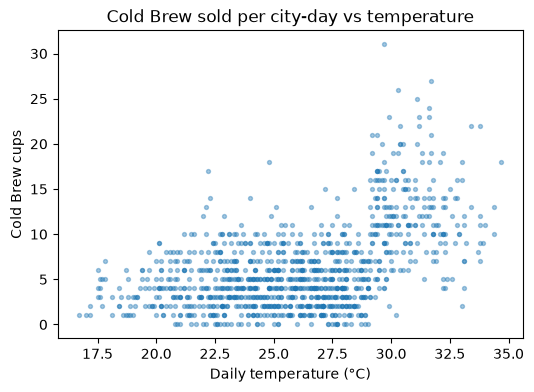

In [29]:
cold_brew = (with_city[with_city["item"] == "Cold Brew"]
             .groupby(["date", "city"], as_index=False)["qty"].sum())
cb = weather.merge(cold_brew, on=["date", "city"], how="left").fillna({"qty": 0})

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(cb["temp_c"], cb["qty"], s=8, alpha=0.4)
ax.set_title("Cold Brew sold per city-day vs temperature")
ax.set_xlabel("Daily temperature (°C)")
ax.set_ylabel("Cold Brew cups")
plt.show()

Below about 29 °C sales sit low and flat; above it they jump. We started from `weather` with a left merge so that hot days with no Cold Brew sold still appear (as 0) instead of vanishing.

In [30]:
cb["hot_day"] = cb["temp_c"] > 29
print(cb.groupby("hot_day")["qty"].mean().round(1))

hot_day
False     4.5
True     12.0
Name: qty, dtype: float64


## 9.9 Common mistakes

| Mistake | What happens | Fix |
|---|---|---|
| Forgetting to parse dates | The column is text: `.dt` fails and sorting is alphabetical | `parse_dates=["timestamp"]` or `pd.to_datetime(col)` |
| Ambiguous day/month formats | `03/04` may be read as 4 March instead of 3 April | Pass `format="%d/%m/%Y"` explicitly |
| Averaging after `groupby` on dates | Days with no sales are missing, so the mean is too high | `reindex(pd.date_range(...), fill_value=0)` |
| Comparing partial resample buckets | The first or last week/month looks like a crash | Check the date range of each bucket; drop or label partial ones |
| Merging a datetime with a time on a plain date | No rows match | Use `dt.normalize()` (or the same dtype) on both sides |
| Slicing an unsorted DatetimeIndex | Slow, or a `KeyError` | `df.sort_index()` first |

## 9.10 Cheat sheet

| Task | Code |
|---|---|
| Parse while loading | `pd.read_csv(path, parse_dates=["timestamp"])` |
| Parse a column with a format | `pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")` |
| Gap between moments | `t2 - t1`, `pd.Timedelta(hours=2)` |
| Parts of a date | `s.dt.hour`, `s.dt.month`, `s.dt.day_of_week`, `s.dt.day_name()` |
| Date without time | `s.dt.normalize()` |
| Month label | `s.dt.to_period("M")` |
| Dates as index | `df.set_index("timestamp").sort_index()` |
| Slice by date string | `df.loc["2024-03"]`, `df.loc["2024-01-01":"2024-01-07"]` |
| Daily / weekly / monthly totals | `s.resample("D").sum()`, `"W"`, `"ME"` |
| Rolling mean | `s.rolling(7).mean()` |
| Previous value, change, % change | `s.shift(1)`, `s.diff()`, `s.pct_change()` |
| Full calendar | `pd.date_range("2024-01-01", "2024-12-31", freq="D")` |
| Fill missing days | `s.reindex(all_days, fill_value=0)` |
| Time zones | `t.tz_localize("Asia/Kolkata").tz_convert("UTC")` |

## 9.11 Exercises

**1.** Which hour of the day brings in the most **revenue** (not the most order lines)? Use `.dt.hour` and `groupby`.

In [31]:
# Solution
rev_by_hour = orders.groupby(orders["timestamp"].dt.hour)["revenue"].sum()
print(rev_by_hour.idxmax(), "o'clock:", rev_by_hour.max())

9 o'clock: 1210380


**2.** Compute the total revenue for each **quarter** of 2024 with `resample`, and the percentage change from one quarter to the next.

In [32]:
# Solution
quarterly = ts_orders["revenue"].resample("QE").sum()
print(pd.DataFrame({"revenue": quarterly,
                    "pct_change": (quarterly.pct_change() * 100).round(1)}))

            revenue  pct_change
timestamp                      
2024-03-31  2443620         NaN
2024-06-30  2395540        -2.0
2024-09-30  2213850        -7.6
2024-12-31  2546830        15.0


**3.** For store S3 only, build the daily revenue series and its 28-day rolling average. Which date has the highest rolling average?

In [33]:
# Solution
s3_daily = ts_orders[ts_orders["store_id"] == "S3"]["revenue"].resample("D").sum()
s3_roll = s3_daily.rolling(28).mean()
print(s3_roll.idxmax().date(), round(s3_roll.max()))

2024-12-31 11463


**4.** How many days in 2024 did store S2 sell **no** Cold Brew at all? Build the daily quantity series, reindex it to the full year and count the zeros.

In [34]:
# Solution
s2_cb = orders[(orders["store_id"] == "S2") & (orders["item"] == "Cold Brew")]
cb_days = s2_cb.groupby(s2_cb["timestamp"].dt.normalize())["qty"].sum()
cb_full = cb_days.reindex(all_days, fill_value=0)
print("days without Cold Brew at S2:", (cb_full == 0).sum())

days without Cold Brew at S2: 62


**5.** Using `sales_weather` from 9.8, compare the mean daily revenue of weekend days and weekdays in Mumbai.

In [35]:
# Solution
mumbai = sales_weather[sales_weather["city"] == "Mumbai"].copy()
mumbai["weekend"] = mumbai["date"].dt.day_of_week >= 5
print(mumbai.groupby("weekend")["revenue"].mean().round(0))

weekend
False     8830.0
True     11341.0
Name: revenue, dtype: float64
